# 1. ECDC ERVISS – respiračné vírusy v EÚ/EHP (týždenne)

**Zdroj:** https://github.com/EU-ECDC/Respiratory_viruses_weekly_data  · popis metodiky: https://erviss.org (Methods)  
**Licencia:** EUPL-1.2 · **Obdobie:** 2022-W25 → aktuálny týždeň · **Krajiny:** EU/EEA vrátane SK

Notebook stiahne 9 CSV súborov, uloží ich do `raw_data/`, ukáže ich štruktúru a vyfiltruje Slovensko.

⚠️ ECDC údaje sa **spätne prepisujú** – zapíšte si dátum stiahnutia. Historické verzie sú v `data/snapshots/` (formát `YYYY-MM-DD_<súbor>.csv`).

In [2]:
# Ak chýbajú knižnice, odkomentujte:
# !pip install pandas requests matplotlib
import os, io, datetime
import requests
import pandas as pd
import matplotlib.pyplot as plt

OUT = "raw_data"
os.makedirs(OUT, exist_ok=True)
DNES = datetime.date.today().isoformat()
print("Dátum stiahnutia:", DNES)

Dátum stiahnutia: 2026-10-26


## Stiahnutie

In [4]:
BASE = "https://raw.githubusercontent.com/EU-ECDC/Respiratory_viruses_weekly_data/main/data/"
SUBORY = {
    "ILIARIRates":                       "ILI/ARI – návštevy u praktika na 100 000",
    "SARIRates":                         "SARI – ťažké respiračné infekcie v nemocniciach",
    "SARITestsDetectionsPositivity":     "SARI – testy, detekcie, pozitivita",
    "sentinelTestsDetectionsPositivity": "sentinel (praktici) – testy, detekcie, pozitivita",
    "nonSentinelTestsDetections":        "ostatné laboratórne detekcie",
    "nonSentinelSeverity":               "hospitalizácie, JIS, úmrtia",
    "activityFluTypeSubtype":            "typy a subtypy chrípky",
    "variants":                          "varianty SARS-CoV-2",
    "sequencingVolumeDetectablePrevalence": "objem sekvenovania",
}

ecdc = {}
for meno, popis in SUBORY.items():
    r = requests.get(BASE + meno + ".csv", timeout=120)
    r.raise_for_status()
    with open(f"{OUT}/ecdc_{meno}.csv", "wb") as f:
        f.write(r.content)
    ecdc[meno] = pd.read_csv(io.BytesIO(r.content))
    print(f"{meno:40s} {len(ecdc[meno]):>8,} riadkov  – {popis}")

ILIARIRates                                36,271 riadkov  – ILI/ARI – návštevy u praktika na 100 000
SARIRates                                  11,074 riadkov  – SARI – ťažké respiračné infekcie v nemocniciach
SARITestsDetectionsPositivity              27,347 riadkov  – SARI – testy, detekcie, pozitivita
sentinelTestsDetectionsPositivity          50,420 riadkov  – sentinel (praktici) – testy, detekcie, pozitivita
nonSentinelTestsDetections                105,200 riadkov  – ostatné laboratórne detekcie
nonSentinelSeverity                        63,466 riadkov  – hospitalizácie, JIS, úmrtia
activityFluTypeSubtype                     31,103 riadkov  – typy a subtypy chrípky
variants                                   34,026 riadkov  – varianty SARS-CoV-2
sequencingVolumeDetectablePrevalence        6,750 riadkov  – objem sekvenovania


## Štruktúra súborov
Všetky sú v *dlhom* formáte: jeden riadok = krajina × týždeň × (patogén) × indikátor × veková skupina.

In [5]:
for meno, df in ecdc.items():
    print(f"\n=== {meno} ===")
    print("stĺpce:", list(df.columns))
    for c in ["survtype", "pathogen", "indicator", "age"]:
        if c in df.columns:
            print(f"  {c}: {sorted(df[c].dropna().unique())[:12]}")


=== ILIARIRates ===
stĺpce: ['survtype', 'countryname', 'yearweek', 'indicator', 'age', 'value']
  survtype: ['primary care syndromic']
  indicator: ['ARIconsultationrate', 'ILIconsultationrate']
  age: ['0-4', '15-64', '5-14', '65+', 'total']

=== SARIRates ===
stĺpce: ['survtype', 'countryname', 'yearweek', 'indicator', 'age', 'value']
  survtype: ['SARI syndromic']
  indicator: ['SARIrate']
  age: ['0-4', '15-64', '5-14', '65+', 'total']

=== SARITestsDetectionsPositivity ===
stĺpce: ['survtype', 'countryname', 'yearweek', 'pathogen', 'pathogentype', 'pathogensubtype', 'indicator', 'age', 'value']
  survtype: ['SARI virological']
  pathogen: ['Influenza', 'RSV', 'SARS-CoV-2']
  indicator: ['detections', 'positivity', 'tests']
  age: ['total']

=== sentinelTestsDetectionsPositivity ===
stĺpce: ['survtype', 'countryname', 'yearweek', 'pathogen', 'pathogentype', 'pathogensubtype', 'indicator', 'age', 'value']
  survtype: ['primary care sentinel']
  pathogen: ['Influenza', 'RSV', 'SARS

In [ ]:
# rozsah týždňov a počet krajín
pd.DataFrame({m: {"od": df.yearweek.min(), "do": df.yearweek.max(),
                  "krajín": df.countryname.nunique(), "riadkov": len(df)}
              for m, df in ecdc.items()}).T

## Slovensko

In [6]:
def iso_tyzden_na_datum(s):
    """'2024-W05' -> pondelok daného ISO týždňa"""
    return pd.to_datetime(s.str.replace("-W", "-") + "-1", format="%G-%V-%u")

In [7]:
sk = {m: df[df.countryname == "Slovakia"].copy() for m, df in ecdc.items()}
for m, df in sk.items():
    print(f"{m:40s} {len(df):>6,} SK riadkov")

for df in sk.values():
    df["datum"] = iso_tyzden_na_datum(df.yearweek)

ILIARIRates                               2,260 SK riadkov
SARIRates                                   846 SK riadkov
SARITestsDetectionsPositivity               864 SK riadkov
sentinelTestsDetectionsPositivity         1,987 SK riadkov
nonSentinelTestsDetections                3,969 SK riadkov
nonSentinelSeverity                       4,494 SK riadkov
activityFluTypeSubtype                      806 SK riadkov
variants                                    769 SK riadkov
sequencingVolumeDetectablePrevalence        225 SK riadkov


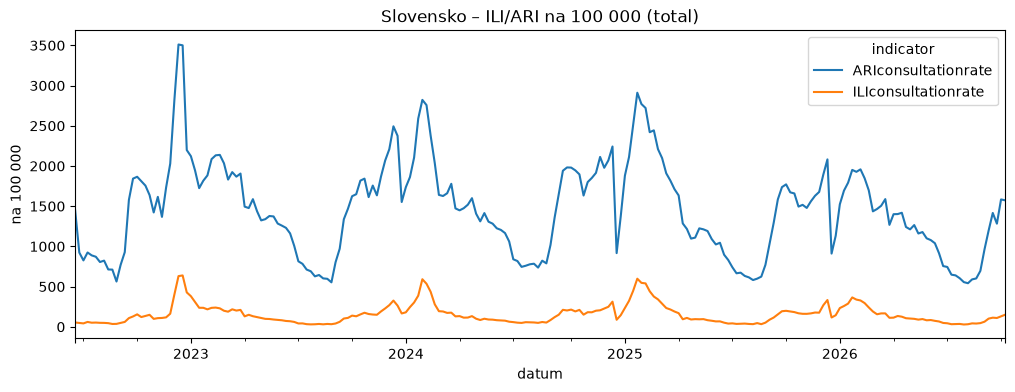

indicator,ARIconsultationrate,ILIconsultationrate
datum,,
2026-09-14,1197.1,101.7
2026-09-21,1415.6,113.3
2026-09-28,1282.5,109.5
2026-10-05,1583.8,129.4
2026-10-12,1572.9,150.2


In [8]:
# Príklad: ILI a ARI na 100 000 obyvateľov, všetky vekové skupiny
ili = sk["ILIARIRates"]
ili_total = ili[ili.age == "total"].pivot_table(index="datum", columns="indicator", values="value")
ili_total.plot(figsize=(12, 4), title="Slovensko – ILI/ARI na 100 000 (total)")
plt.ylabel("na 100 000"); plt.show()
ili_total.tail()

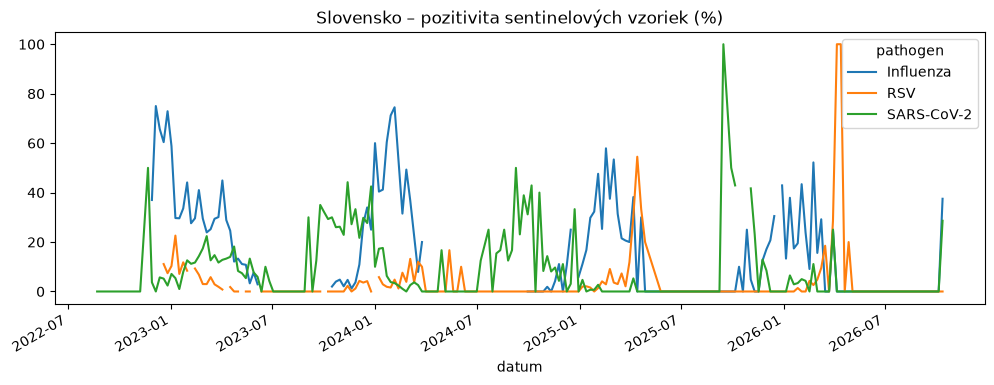

In [9]:
# Príklad: pozitivita sentinelových vzoriek podľa patogénu
pos = sk["sentinelTestsDetectionsPositivity"]
pos = pos[(pos.indicator == "positivity") & (pos.age == "total")]
pos.pivot_table(index="datum", columns="pathogen", values="value").plot(
    figsize=(12, 4), title="Slovensko – pozitivita sentinelových vzoriek (%)")
plt.show()

## Kontrola kvality
V lete 2026 ECDC prechádzalo z TESSy na EpiPulse – skontrolujte medzery v SK radoch.

In [ ]:
for m, df in sk.items():
    if df.empty: continue
    vsetky = pd.date_range(df.datum.min(), df.datum.max(), freq="W-MON")
    chyba = vsetky.difference(df.datum.unique())
    print(f"{m:40s} chýbajúcich týždňov: {len(chyba):3d}", list(chyba.strftime("%G-W%V"))[:8])

In [10]:
# Uloženie SK výberu
pd.concat([df.assign(subor=m) for m, df in sk.items()]).to_csv(f"{OUT}/ecdc_SK_vsetko.csv", index=False)
print("Uložené:", f"{OUT}/ecdc_SK_vsetko.csv", "| stiahnuté:", DNES)

Uložené: raw_data/ecdc_SK_vsetko.csv | stiahnuté: 2026-10-26
